# Elastic Deformation of Two-Dimensional Objects
**Group 02 · Numerical Linear Algebra and PDEs · companion notebook to `Group02_Report.pdf`**

This notebook reproduces every number, table and figure in the report from scratch. It runs top to bottom with no other files.

**What it does**
1. Builds the linear system $A\mathbf{x}=\mathbf{b}$ for a thin elastic plate using linear triangular finite elements (report §1–2).
2. Solves a small system by hand-checkable direct methods (report §4).
3. Compares direct and iterative solvers on a larger system under one shared protocol (report §3–4).
4. Studies how conditioning and solver effort change with mesh refinement (report §4).
5. Validates the solution with equilibrium checks and an exact test case (report §4).
6. Runs the experiments on additional objects: a long rectangle and a square with a hole (report §5–6).
7. Exports every result table and figure to `outputs/` (Part 8).

**Units** throughout: metres, newtons, pascals.

**Run time:** a few minutes on a laptop. Most of it is Gauss–Seidel and the iteration-capped methods in Part 3.

## 0. Setup and dependencies

Required: `numpy`, `scipy`, `matplotlib` (standard scientific Python), and `triangle` (a Python interface to J. R. Shewchuk's Triangle mesh generator, used only in Part 6). The next cell installs `triangle` if it is missing.

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("triangle") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "triangle"])

import json, platform
from time import perf_counter

import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
import triangle as tr
from scipy.linalg import cho_factor, cho_solve, eigvalsh, inv, lu_factor, lu_solve
from scipy.sparse import coo_matrix, csr_matrix, diags, tril
from scipy.sparse.linalg import cg, eigsh, gmres, minres, splu, spsolve_triangular

np.set_printoptions(precision=4, suppress=False, linewidth=110)
from pathlib import Path
OUT = Path("outputs")
(OUT / "results").mkdir(parents=True, exist_ok=True); (OUT / "figures").mkdir(parents=True, exist_ok=True)
def save(fig, name):
    fig.savefig(OUT / "figures" / f"{name}.png", dpi=180, bbox_inches="tight")
print("python", platform.python_version(), "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| matplotlib", matplotlib.__version__, "| triangle", getattr(tr, "__version__", "installed"))
print(platform.platform())

python 3.12.2 | numpy 1.26.4 | scipy 1.13.1 | matplotlib 3.9.2 | triangle 20250106
macOS-14.8.9-arm64-arm-64bit


## 1. Physical model (report §1–2)

A thin steel plate of thickness $t$ lies in the $xy$-plane. Its left edge is clamped and a uniform traction $p$ pulls its right edge. We want the displacement field $\mathbf{u}(x,y) = (u_x, u_y)$.

The chain of ideas:

| Quantity | Meaning | Relation |
|---|---|---|
| displacement $\mathbf{u}$ | how far each point moves | unknown |
| strain $\boldsymbol\varepsilon = (\varepsilon_{xx}, \varepsilon_{yy}, \gamma_{xy})$ | local stretching and shearing | derivatives of $\mathbf{u}$ |
| stress $\boldsymbol\sigma = (\sigma_{xx}, \sigma_{yy}, \tau_{xy})$ | internal force per area | $\boldsymbol\sigma = D\,\boldsymbol\varepsilon$ (Hooke's law) |
| equilibrium | every piece is in force balance | gives $K\mathbf{d} = \mathbf{f} + \mathbf{r}$ |

**Plane stress** (the plate is thin, so stresses through the thickness vanish) gives the material matrix

$$
D = \frac{E}{1-\nu^2}\begin{pmatrix}1 & \nu & 0\\ \nu & 1 & 0\\ 0 & 0 & \tfrac{1-\nu}{2}\end{pmatrix},
$$

with Young's modulus $E$ (stiffness) and Poisson's ratio $\nu$ (sideways contraction). $D$ is symmetric positive definite whenever $E>0$ and $-1<\nu<1/2$.

**Baseline case** (used in Parts 2–5): $1\times1$ m steel plate, $E = 200$ GPa, $\nu = 0.3$, $t = 1$ cm, $p = 100$ MPa, so the total pull is $p\,t\,(1\text{ m}) = 10^6$ N.

In [2]:
E, NU, T, P = 200e9, 0.3, 0.01, 100e6     # Pa, -, m, Pa

def material_matrix(E, nu):
    # Plane-stress constitutive matrix D in sigma = D eps (engineering shear strain).
    if not (E > 0 and -1 < nu < 0.5):
        raise ValueError("need E > 0 and -1 < nu < 0.5 for a positive definite D")
    return E / (1 - nu**2) * np.array([[1, nu, 0], [nu, 1, 0], [0, 0, (1 - nu) / 2]])

D = material_matrix(E, NU)
print("D [GPa] =\n", D / 1e9)
print("eigenvalues of D [GPa]:", np.linalg.eigvalsh(D) / 1e9, "-> all positive, D is SPD")

D [GPa] =
 [[219.7802  65.9341   0.    ]
 [ 65.9341 219.7802   0.    ]
 [  0.       0.      76.9231]]
eigenvalues of D [GPa]: [ 76.9231 153.8462 285.7143] -> all positive, D is SPD


## 2. From triangles to the stiffness matrix (report §2)

We cut the plate into triangles and track only the corner (node) displacements. Node $i$ has two unknowns $(u_{x,i}, u_{y,i})$. We order them as $\mathbf{d} = [u_{x,0}, u_{y,0}, u_{x,1}, u_{y,1}, \dots]$.

Inside one triangle the displacement varies **linearly** between its three corners, so the strain is constant there: $\boldsymbol\varepsilon = B\,\mathbf{d}_e$, where $\mathbf{d}_e$ holds the triangle's 6 corner displacements. For corners $(x_k, y_k)$ in counter-clockwise order, with $b_i = y_j - y_k$, $c_i = x_k - x_j$ ($i,j,k$ cyclic) and area $\Delta$:

$$
B = \frac{1}{2\Delta}\begin{pmatrix} b_1 & 0 & b_2 & 0 & b_3 & 0\\ 0 & c_1 & 0 & c_2 & 0 & c_3\\ c_1 & b_1 & c_2 & b_2 & c_3 & b_3\end{pmatrix},
\qquad
K_e = t\,\Delta\, B^\top D B \quad (6\times 6).
$$

The global stiffness matrix $K$ is the sum of all $K_e$, each placed in the rows and columns of its triangle's unknowns (**assembly**). Nodes shared by several triangles collect contributions from each.

In [3]:
def strain_displacement(xy):
    # Return (B, area) for one triangle with CCW corner coordinates xy (3, 2).
    (x1, y1), (x2, y2), (x3, y3) = xy
    two_area = (x2 - x1) * (y3 - y1) - (x3 - x1) * (y2 - y1)
    if two_area <= 0:
        raise ValueError("triangle is degenerate or not counter-clockwise")
    b = np.array([y2 - y3, y3 - y1, y1 - y2])
    c = np.array([x3 - x2, x1 - x3, x2 - x1])
    B = np.zeros((3, 6))
    B[0, 0::2] = b          # eps_xx   = du_x/dx
    B[1, 1::2] = c          # eps_yy   = du_y/dy
    B[2, 0::2] = c          # gamma_xy = du_x/dy + du_y/dx
    B[2, 1::2] = b
    return B / two_area, two_area / 2


def element_stiffness(xy, D, t):
    B, area = strain_displacement(xy)
    return t * area * B.T @ D @ B


def assemble(nodes, triangles, E, nu, t):
    # Global stiffness K (sparse CSR, 2N x 2N). Duplicate entries from shared nodes are summed.
    D = material_matrix(E, nu)
    rows, cols, vals = [], [], []
    for tri in triangles:
        Ke = element_stiffness(nodes[tri], D, t)
        dofs = np.column_stack([2 * tri, 2 * tri + 1]).ravel()
        rows.append(np.repeat(dofs, 6)); cols.append(np.tile(dofs, 6)); vals.append(Ke.ravel())
    n = 2 * len(nodes)
    K = coo_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))), shape=(n, n)).tocsr()
    K.sum_duplicates()
    return K

**Quick check on one triangle.** $K_e$ must be symmetric. It must also have exactly three zero eigenvalues: two rigid translations and one rigid rotation move the triangle without straining it, so they store no energy.

In [4]:
xy = np.array([[0.0, 0.0], [1.0, 0.0], [0.0, 1.0]])
Ke = element_stiffness(xy, D, T)
ev = np.linalg.eigvalsh(Ke)
print("symmetric:", np.allclose(Ke, Ke.T))
print("eigenvalues of K_e / max:", np.round(ev / ev.max(), 12))

symmetric: True
eigenvalues of K_e / max: [-0.      0.      0.      0.2792  0.4477  1.    ]


### Loads, supports and the reduced system

* **Loads.** A constant line load $\mathbf{q}$ (N/m) on a boundary edge of length $\ell$ gives each of its two end nodes the force $\mathbf{q}\,\ell/2$. For a traction $p$ on a plate of thickness $t$, $\mathbf{q} = (t\,p, 0)$.
* **Supports.** Clamped nodes have prescribed displacement $0$. Split the unknowns into free ($F$) and constrained ($C$):

$$
\begin{pmatrix}K_{FF} & K_{FC}\\ K_{CF} & K_{CC}\end{pmatrix}\begin{pmatrix}\mathbf{d}_F\\ \mathbf{d}_C\end{pmatrix} = \begin{pmatrix}\mathbf{f}_F\\ \mathbf{f}_C + \mathbf{r}_C\end{pmatrix}
\quad\Longrightarrow\quad
\underbrace{K_{FF}}_{A}\,\underbrace{\mathbf{d}_F}_{\mathbf{x}} = \underbrace{\mathbf{f}_F - K_{FC}\,\mathbf{d}_C}_{\mathbf{b}}.
$$

The support reactions $\mathbf{r}_C$ follow afterwards from the second block row.

**Why $A$ is SPD.** The stored energy is $\tfrac12\mathbf{d}^\top K\mathbf{d}\ge0$. On its own, $K$ is singular: rigid motions store no energy. Clamping removes every rigid motion, so $\mathbf{x}^\top A\mathbf{x}>0$ for every $\mathbf{x}\neq0$.

In [5]:
def constant_edge_load(nodes, edges, q):
    # Nodal forces (length 2N) for a constant line load q = (qx, qy) [N/m] on the given edges.
    edges = np.asarray(edges)
    lengths = np.linalg.norm(nodes[edges[:, 1]] - nodes[edges[:, 0]], axis=1)
    forces = np.zeros_like(nodes)
    for end in (0, 1):
        np.add.at(forces, edges[:, end], lengths[:, None] * np.asarray(q, float) / 2)
    return forces.ravel()


def reduce_system(K, f, constrained, values):
    # Return A, b, free, d; afterwards fill d[free] with the solution of A x = b.
    c = np.asarray(constrained, dtype=int)
    free = np.setdiff1d(np.arange(f.size), c)
    d = np.zeros(f.size); d[c] = values
    return K[free][:, free], f[free] - K[free][:, c] @ values, free, d


def xy_dofs(node_ids):
    node_ids = np.asarray(node_ids)
    return np.column_stack([2 * node_ids, 2 * node_ids + 1]).ravel()

### Structured mesh of a rectangle

Parts 2–5 use a regular grid: $n_x\times n_y$ square cells, each cut into two triangles along the bottom-left to top-right diagonal. This gives $(n_x+1)(n_y+1)$ nodes.

In [6]:
def rectangle_mesh(Lx, Ly, nx, ny):
    xs, ys = np.linspace(0, Lx, nx + 1), np.linspace(0, Ly, ny + 1)
    X, Y = np.meshgrid(xs, ys)
    nodes = np.column_stack([X.ravel(), Y.ravel()])
    idx = lambda i, j: i + j * (nx + 1)
    tris = []
    for j in range(ny):
        for i in range(nx):
            n0, n1, n2, n3 = idx(i, j), idx(i + 1, j), idx(i + 1, j + 1), idx(i, j + 1)
            tris += [(n0, n1, n2), (n0, n2, n3)]
    side = {"left": np.array([idx(0, j) for j in range(ny + 1)]),
            "right": np.array([idx(nx, j) for j in range(ny + 1)])}
    return nodes, np.array(tris), side


def plate_case(nx, ny=None, *, Lx=1.0, Ly=1.0, support="clamp"):
    # Baseline plate. support='clamp': u = 0 on the left edge.
    # support='roller': u_x = 0 on the left edge and u_y = 0 at (0, 0) only (exact solution known).
    ny = nx if ny is None else ny
    nodes, tris, side = rectangle_mesh(Lx, Ly, nx, ny)
    K = assemble(nodes, tris, E, NU, T)
    right_edges = np.column_stack([side["right"][:-1], side["right"][1:]])
    f = constant_edge_load(nodes, right_edges, [T * P, 0.0])
    if support == "clamp":
        c = xy_dofs(side["left"])
    else:
        c = np.append(2 * side["left"], 2 * side["left"][0] + 1)
    c = np.sort(c)
    A, b, free, d = reduce_system(K, f, c, np.zeros(c.size))
    return dict(nodes=nodes, triangles=tris, side=side, K=K, f=f, constrained=c, free=free, d=d, A=A, b=b)

## 3. A small system you can inspect (report §4)

A $2\times2$-cell mesh has 9 nodes. The 3 left nodes are clamped, leaving $6$ free nodes and **12 unknowns**. At this size we can print $A$ and solve it with every direct method.

In [7]:
small = plate_case(2)
A_s, b_s = small["A"].toarray(), small["b"]
print("unknowns:", len(b_s), "| stored nonzeros:", small["A"].nnz, "of", A_s.size)
print("symmetric:", np.allclose(A_s, A_s.T))
ev = eigvalsh(A_s)
print(f"lambda_min = {ev[0]:.4e}, lambda_max = {ev[-1]:.4e}  -> all positive: A is SPD")
print(f"condition number kappa_2 = lambda_max / lambda_min = {ev[-1] / ev[0]:.1f}")
print("\nb [N] (nonzero only at the loaded right-edge x-components):\n", b_s)

unknowns: 12 | stored nonzeros: 96 of 144
symmetric: True
lambda_min = 1.0731e+08, lambda_max = 1.0280e+10  -> all positive: A is SPD
condition number kappa_2 = lambda_max / lambda_min = 95.8

b [N] (nonzero only at the loaded right-edge x-components):
 [     0.      0. 250000.      0.      0.      0. 500000.      0.      0.      0. 250000.      0.]


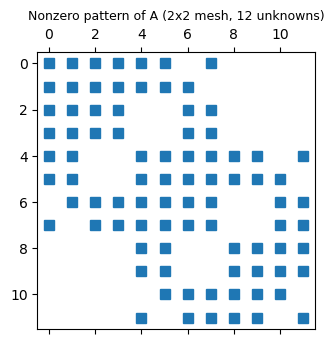

In [8]:
fig, ax = plt.subplots(figsize=(4, 3.6))
ax.spy(A_s, markersize=7)
ax.set_title("Nonzero pattern of A (2x2 mesh, 12 unknowns)", fontsize=9)
save(fig, "structured_small_sparsity"); plt.show()

In [9]:
x_direct = {
    "PA = LU":  lu_solve(lu_factor(A_s), b_s),
    "inverse":  inv(A_s) @ b_s,
    "Cholesky": cho_solve(cho_factor(A_s, lower=True), b_s),
}
nb = np.linalg.norm(b_s)
for name, x in x_direct.items():
    print(f"{name:9s} relative residual ||b - Ax|| / ||b|| = {np.linalg.norm(b_s - A_s @ x) / nb:.2e}")
d = small["d"].copy(); d[small["free"]] = x_direct["Cholesky"]
print("\nright-edge horizontal displacements [mm]:", d.reshape(-1, 2)[small["side"]["right"], 0] * 1e3)

PA = LU   relative residual ||b - Ax|| / ||b|| = 6.15e-16
inverse   relative residual ||b - Ax|| / ||b|| = 8.53e-16
Cholesky  relative residual ||b - Ax|| / ||b|| = 7.72e-16

right-edge horizontal displacements [mm]: [0.5112 0.4822 0.4678]


## 4. Solver comparison on a larger system (report §3–4)

A $20\times20$ mesh gives 840 unknowns. Every method uses the **same protocol**:

* the same $A$ and $\mathbf{b}$, starting guess $\mathbf{x}_0 = 0$;
* stop when the relative residual $\|\mathbf{b}-A\mathbf{x}_k\|/\|\mathbf{b}\| < 10^{-8}$, checked independently of each method's own stopping test;
* at most 20,000 iterations;
* timing is the best of 3 runs (timings depend on the machine; iteration counts do not).

| Method | Requirement on $A$ | Expectation here |
|---|---|---|
| Jacobi | $\rho(I - D_A^{-1}A) < 1$ | not guaranteed even for SPD |
| Damped Jacobi ($\omega = 0.5$) | $\omega < 2/\lambda_{\max}(D_A^{-1}A)$ | converges, slowly |
| Gauss–Seidel | SPD is sufficient | converges, slowly |
| Steepest descent (SD) | SPD | converges, rate set by $\kappa$ |
| Conjugate gradient (CG) | SPD | converges in $O(\sqrt{\kappa})$ iterations |
| CG with diagonal preconditioner (PCG) | SPD and SPD preconditioner | slightly faster than CG |
| MINRES | symmetric | works; it does not use positive definiteness |
| GMRES (no restart) | any nonsingular $A$ | works, but stores a growing basis |

($D_A$ is the diagonal of $A$.)

In [10]:
TOL, CAP = 1e-8, 20_000
METHODS = ["Jacobi", "Damped Jacobi", "Gauss-Seidel", "SD", "CG", "PCG (diagonal)", "MINRES", "GMRES (full)"]


def iterative(A, b, method, *, cap=CAP, tol=TOL, history=True):
    # Zero initial guess. Returns x, iterations, status, residual history.
    # GMRES history is its internal (Arnoldi) residual estimate; its final residual is checked separately.
    x = np.zeros_like(b); nb = np.linalg.norm(b)
    hist = [1.0] if history else []
    count, last = 0, x.copy()

    class TargetReached(Exception):
        pass

    def monitor(xk):
        nonlocal count, last
        count += 1
        if method == "MINRES" or history:
            rr = float(np.linalg.norm(b - A @ xk) / nb)
            if history: hist.append(rr)
            if method == "MINRES" and rr < tol:      # MINRES stops on the shared true-residual target
                last = xk.copy(); raise TargetReached

    def arnoldi(res):
        nonlocal count
        count += 1
        if history: hist.append(float(res))

    if method in {"CG", "PCG (diagonal)"}:
        M = diags(1 / A.diagonal()) if method.startswith("PCG") else None
        x, info = cg(A, b, rtol=tol, atol=0, maxiter=cap, M=M, callback=monitor)
        status = "target" if info == 0 else f"info={info}"
    elif method == "GMRES (full)":
        x, info = gmres(A, b, rtol=tol, atol=0, restart=A.shape[0], maxiter=cap,
                        callback=arnoldi, callback_type="legacy")
        status = "target" if info == 0 else f"info={info}"
    elif method == "MINRES":
        try:
            x, info = minres(A, b, rtol=0, maxiter=cap, callback=monitor)
            status = f"info={info}"
        except TargetReached:
            x, status = last, "target"
    else:
        Dg = A.diagonal()
        L = tril(A, format="csr") if method == "Gauss-Seidel" else None
        U = (A - L).tocsr() if L is not None else None
        r, status = b.copy(), "iteration cap"
        for count in range(1, cap + 1):
            if method == "Jacobi":          x += r / Dg
            elif method == "Damped Jacobi": x += 0.5 * r / Dg
            elif method == "Gauss-Seidel":  x = spsolve_triangular(L, b - U @ x, lower=True)
            elif method == "SD":            Ar = A @ r; x += ((r @ r) / (r @ Ar)) * r
            r = b - A @ x
            rr = float(np.linalg.norm(r) / nb)
            if history: hist.append(rr)
            if not np.isfinite(rr) or rr > 1e10: status = "diverged"; break
            if rr < tol: status = "target"; break
    return x, count, status, hist

Sanity check on a $2\times2$ SPD system with a known answer. Every method must recover $\mathbf{x} = (1,-2)$.

In [11]:
A_t = csr_matrix([[4.0, 1.0], [1.0, 3.0]]); x_t = np.array([1.0, -2.0])
for m in METHODS:
    x, k, s, _ = iterative(A_t, A_t @ x_t, m, cap=2000)
    assert np.linalg.norm(x - x_t) < 1e-7, m
print("all methods recover the known solution")

all methods recover the known solution


In [12]:
case = plate_case(20)
A, b = case["A"], case["b"]
lu = splu(A.tocsc()); x_ref = lu.solve(b)          # sparse direct reference solution
print(f"unknowns: {len(b)}, stored nonzeros: {A.nnz} ({100 * A.nnz / len(b)**2:.2f}% of the matrix)")
print(f"sparse LU reference: relative residual {np.linalg.norm(b - A @ x_ref) / np.linalg.norm(b):.1e}")

TIMING_RUNS = 3
rows, histories = [], {}
for m in METHODS:
    x, k, status, hist = iterative(A, b, m)
    histories[m] = hist
    times = []
    for _ in range(TIMING_RUNS):
        t0 = perf_counter(); iterative(A, b, m, history=False); times.append(perf_counter() - t0)
    rr = np.linalg.norm(b - A @ x) / np.linalg.norm(b)
    err = np.linalg.norm(x - x_ref) / np.linalg.norm(x_ref)
    rows.append((m, k, status, rr, err, min(times)))

print(f"\n{'method':16s} {'iterations':>10s} {'status':>14s} {'rel. residual':>14s} {'rel. error':>11s} {'best time [s]':>14s}")
for m, k, s, rr, err, tm in rows:
    print(f"{m:16s} {k:10d} {s:>14s} {rr:14.2e} {err:11.2e} {tm:14.4f}")

unknowns: 840, stored nonzeros: 11112 (1.57% of the matrix)
sparse LU reference: relative residual 3.1e-14



method           iterations         status  rel. residual  rel. error  best time [s]
Jacobi                   49       diverged       1.32e+10    3.38e+07         0.0006
Damped Jacobi         20000  iteration cap       4.76e-06    8.73e-05         0.2213
Gauss-Seidel          19136         target       1.00e-08    1.74e-07        78.6533
SD                    20000  iteration cap       3.08e-06    4.22e-05         0.3890
CG                      242         target       9.23e-09    9.71e-10         0.0039
PCG (diagonal)          226         target       8.40e-09    4.85e-10         0.0045
MINRES                  236         target       9.66e-09    6.14e-09         0.0084
GMRES (full)            228         target       9.48e-09    5.97e-09         0.2163


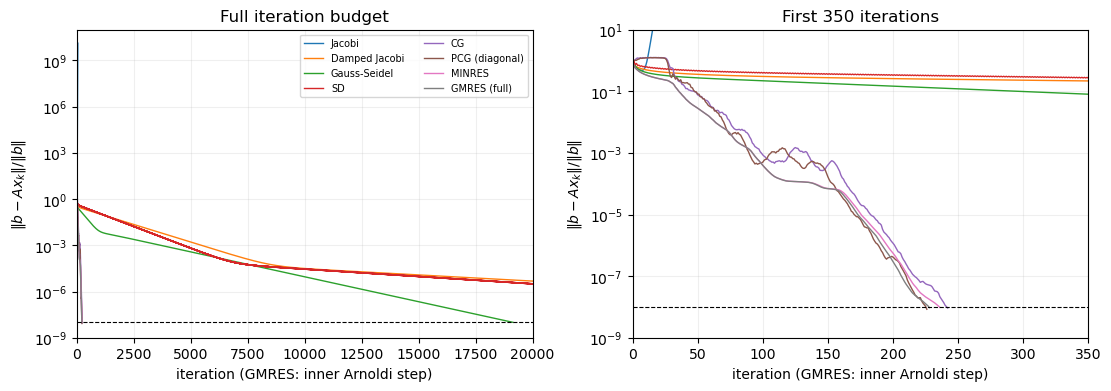

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
for name, hist in histories.items():
    for ax in axes:
        ax.semilogy(range(len(hist)), hist, label=name, lw=1)
for ax in axes:
    ax.axhline(TOL, color="black", ls="--", lw=0.8)
    ax.set_xlabel("iteration (GMRES: inner Arnoldi step)"); ax.set_ylabel(r"$\|b-Ax_k\|/\|b\|$"); ax.grid(alpha=0.2)
axes[0].set(xlim=(0, CAP), ylim=(1e-9, 1e11), title="Full iteration budget")
axes[1].set(xlim=(0, 350), ylim=(1e-9, 10), title="First 350 iterations")
axes[0].legend(fontsize=7, ncol=2)
save(fig, "structured_residual_histories"); plt.show()

**Why Jacobi diverges although $A$ is SPD.** Jacobi converges exactly when the spectral radius $\rho(I - D_A^{-1}A) < 1$. Since $D_A^{-1}A$ is similar to the SPD matrix $S = D_A^{-1/2} A D_A^{-1/2}$, its eigenvalues are real and positive. So $\rho = \max(|1-\lambda_{\min}(S)|, |1-\lambda_{\max}(S)|)$, and Jacobi fails as soon as $\lambda_{\max}(S) > 2$.

In [14]:
H = diags(1 / np.sqrt(A.diagonal()))
S = (H @ A @ H).tocsr()
s_lo = eigsh(S, k=1, which="SA", return_eigenvectors=False, tol=1e-10, v0=np.ones(len(b)))[0]
s_hi = eigsh(S, k=1, which="LA", return_eigenvectors=False, tol=1e-10, v0=np.ones(len(b)))[0]
print(f"lambda(S) in [{s_lo:.4f}, {s_hi:.4f}]")
print(f"Jacobi spectral radius rho = {max(abs(1 - s_lo), abs(1 - s_hi)):.4f}  (> 1: diverges)")
print(f"damped Jacobi converges for omega < 2 / lambda_max(S) = {2 / s_hi:.4f}  (we use 0.5)")

lambda(S) in [0.0004, 2.9601]
Jacobi spectral radius rho = 1.9601  (> 1: diverges)
damped Jacobi converges for omega < 2 / lambda_max(S) = 0.6757  (we use 0.5)


## 5. Mesh refinement: conditioning and solver effort (report §4)

Halving the cell size $h$ should multiply the condition number by about 4 ($\kappa = O(h^{-2})$). Since CG needs $O(\sqrt{\kappa})$ iterations, its iteration count should roughly double each time.

In [15]:
def extreme_eigs(A):
    # Smallest eigenvalue by shift-invert around 0 (fast with a sparse factorisation), largest directly.
    lo = eigsh(A.tocsc(), k=1, sigma=0, which="LM", return_eigenvectors=False)[0]
    hi = eigsh(A, k=1, which="LA", return_eigenvectors=False, tol=1e-10, v0=np.ones(A.shape[0]))[0]
    return lo, hi

refine = []
for n in (10, 20, 40):
    c_n = plate_case(n)
    lo, hi = extreme_eigs(c_n["A"])
    _, k_cg, _, _ = iterative(c_n["A"], c_n["b"], "CG", history=False)
    d_n = c_n["d"].copy(); d_n[c_n["free"]] = splu(c_n["A"].tocsc()).solve(c_n["b"])
    top_right = c_n["side"]["right"][-1]
    refine.append((n, len(c_n["b"]), c_n["A"].nnz, hi / lo, k_cg, d_n[2 * top_right] * 1e3))

print(f"{'cells':>6s} {'unknowns':>9s} {'nnz':>7s} {'kappa':>10s} {'CG its':>7s} {'u_x top-right [mm]':>19s}")
for r in refine:
    print(f"{r[0]:4d}^2 {r[1]:9d} {r[2]:7d} {r[3]:10.0f} {r[4]:7d} {r[5]:19.5f}")
print("kappa ratios:", [f"{refine[i+1][3] / refine[i][3]:.2f}" for i in range(2)],
      "| CG ratios:", [f"{refine[i+1][4] / refine[i][4]:.2f}" for i in range(2)])

 cells  unknowns     nnz      kappa  CG its  u_x top-right [mm]
  10^2       220    2752       2469     120             0.49385
  20^2       840   11112       9104     242             0.49551
  40^2      3280   44632      34548     469             0.49607
kappa ratios: ['3.69', '3.79'] | CG ratios: ['2.02', '1.94']


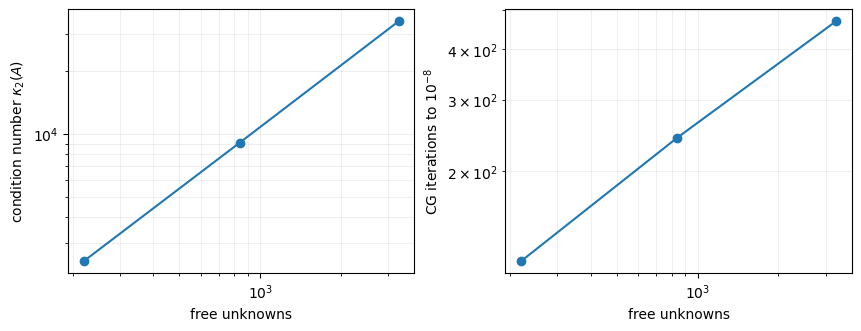

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.2), constrained_layout=True)
ns = [r[1] for r in refine]
axes[0].loglog(ns, [r[3] for r in refine], "o-"); axes[0].set_ylabel(r"condition number $\kappa_2(A)$")
axes[1].loglog(ns, [r[4] for r in refine], "o-"); axes[1].set_ylabel("CG iterations to $10^{-8}$")
for ax in axes:
    ax.set_xlabel("free unknowns"); ax.grid(alpha=0.2, which="both")
save(fig, "structured_refinement"); plt.show()

## 6. Validation (report §4)

"All solvers agree" only shows that the *linear system* was solved correctly. To check the *model* we test:

1. **Equilibrium.** Support reactions plus applied loads must sum to zero force and zero moment.
2. **An exact solution.** With a roller support (only $u_x = 0$ on the left edge, plus $u_y = 0$ at one corner) the plate is in uniform tension. The exact displacement $u_x = p\,x/E$, $u_y = -\nu\,p\,y/E$ is linear, so linear triangles must reproduce it to rounding error.
3. **Sensitivity.** A relative perturbation of $10^{-6}$ in $\mathbf{b}$ may change $\mathbf{x}$ by at most $\kappa \cdot 10^{-6}$ (relative).

In [17]:
def equilibrium(case, x):
    d = case["d"].copy(); d[case["free"]] = x
    r = case["K"] @ d - case["f"]                         # nonzero only at supports: the reactions
    reac = np.zeros_like(r); reac[case["constrained"]] = r[case["constrained"]]
    total = (reac + case["f"]).reshape(-1, 2)
    xy = case["nodes"]
    return d, total.sum(axis=0), float(np.sum(xy[:, 0] * total[:, 1] - xy[:, 1] * total[:, 0]))

d20, F_net, M_net = equilibrium(case, x_ref)
print(f"applied load: {case['f'].reshape(-1, 2).sum(axis=0)} N")
print(f"net force  (loads + reactions): {F_net} N")
print(f"net moment (loads + reactions): {M_net:.2e} N m")

roller = plate_case(6, 4, Lx=2.0, Ly=1.0, support="roller")
d_r = roller["d"].copy(); d_r[roller["free"]] = splu(roller["A"].tocsc()).solve(roller["b"])
exact = np.column_stack([P * roller["nodes"][:, 0] / E, -NU * P * roller["nodes"][:, 1] / E]).ravel()
print(f"\nroller test: relative error vs exact solution = {np.linalg.norm(d_r - exact) / np.linalg.norm(exact):.1e}")

rng = np.random.default_rng(2026)
db = rng.normal(size=len(b)); db *= 1e-6 * np.linalg.norm(b) / np.linalg.norm(db)
dx = lu.solve(b + db) - x_ref
lo20, hi20 = extreme_eigs(A)
print(f"\nperturbation: ||db||/||b|| = 1e-6 -> ||dx||/||x|| = {np.linalg.norm(dx) / np.linalg.norm(x_ref):.2e}"
      f"  (bound kappa * 1e-6 = {hi20 / lo20 * 1e-6:.2e})")

applied load: [1000000.       0.] N
net force  (loads + reactions): [-9.1313e-10 -2.9140e-09] N
net moment (loads + reactions): 5.97e-09 N m

roller test: relative error vs exact solution = 7.9e-16

perturbation: ||db||/||b|| = 1e-6 -> ||dx||/||x|| = 4.51e-07  (bound kappa * 1e-6 = 9.10e-03)


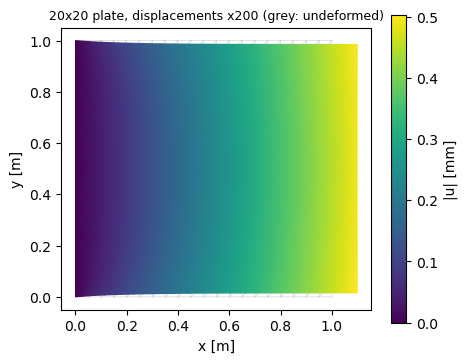

maximum right-edge u_x = 0.4967 mm


In [18]:
def plot_deformed(ax, nodes, tris, d, scale, title):
    u = d.reshape(-1, 2)
    ax.triplot(nodes[:, 0], nodes[:, 1], tris, color="0.8", lw=0.4)
    tp = ax.tripcolor(*(nodes + scale * u).T, tris, np.linalg.norm(u, axis=1) * 1e3, shading="gouraud", cmap="viridis")
    ax.set_aspect("equal"); ax.set_title(title, fontsize=9); ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
    return tp

fig, ax = plt.subplots(figsize=(5, 4))
tp = plot_deformed(ax, case["nodes"], case["triangles"], d20, 200, "20x20 plate, displacements x200 (grey: undeformed)")
fig.colorbar(tp, ax=ax, label="|u| [mm]")
save(fig, "structured_deformed_20x20"); plt.show()
print(f"maximum right-edge u_x = {d20.reshape(-1, 2)[case['side']['right'], 0].max() * 1e3:.4f} mm")

## 7. Other objects and experiments (report §5–6)

> **Status and source.** This part implements the case specification of report §5 exactly as committed in the group repository: `draft/sections/05-objects-and-experiments/cases.json` at commit `2b23fd5` (merge of PR #7). It is embedded below so the notebook stays self-contained. The group has merged it as a working draft but has **not yet formally approved** the object selection. Results here are valid for this specification.

Three objects share the baseline material, thickness, clamp and traction:

* **S**: the unit square (control);
* **R**: a $2\times1$ m rectangle (the load is farther from the clamp);
* **H**: the unit square with a central $0.2\times0.2$ m opening.

Meshes come from **Triangle** (`p`: respect the boundary polygon, `q25`: minimum angle 25°, `a`: maximum triangle area). Boundary split points are inserted on the left and right edges, so the load patches and the partial clamp start and end exactly at nodes. These unstructured meshes are separate from the structured meshes of Parts 3–6, and their results should not be mixed with them.

In [19]:
CASES_SOURCE = 'Pueblo98/NLA draft/sections/05-objects-and-experiments/cases.json @ 2b23fd5 (merged PR #7)'
CASES = json.loads(r'''{
 "status": "PROPOSED, NOT APPROVED OR EXECUTED",
 "units": {
  "length": "m",
  "force": "N",
  "stress": "Pa"
 },
 "baseline": {
  "model": "plane stress, homogeneous isotropic linear elasticity",
  "E_Pa": 200000000000.0,
  "nu": 0.3,
  "thickness_m": 0.01,
  "body_force": [
   0,
   0
  ],
  "prescribed_displacement_m": [
   0,
   0
  ],
  "support": "ux=uy=0 along the whole left edge",
  "loaded_edge": "whole right edge",
  "traction_Pa": [
   100000000.0,
   0
  ],
  "total_force_N": [
   1000000.0,
   0
  ],
  "other_edges": "traction free, including hole"
 },
 "objects": [
  {
   "id": "S",
   "name": "square control",
   "outer_ccw_m": [
    [
     0.0,
     0.0
    ],
    [
     1.0,
     0.0
    ],
    [
     1.0,
     1.0
    ],
    [
     0.0,
     1.0
    ]
   ],
   "holes_cw_m": [],
   "hole_seeds_m": [],
   "left_x_m": 0.0,
   "right_x_m": 1.0,
   "left_boundary_splits_y_m": [
    0.0,
    0.25,
    0.75,
    1.0
   ],
   "right_boundary_splits_y_m": [
    0.0,
    0.25,
    0.375,
    0.5,
    0.625,
    0.75,
    1.0
   ]
  },
  {
   "id": "R",
   "name": "long rectangle",
   "outer_ccw_m": [
    [
     0.0,
     0.0
    ],
    [
     2.0,
     0.0
    ],
    [
     2.0,
     1.0
    ],
    [
     0.0,
     1.0
    ]
   ],
   "holes_cw_m": [],
   "hole_seeds_m": [],
   "left_x_m": 0.0,
   "right_x_m": 2.0,
   "left_boundary_splits_y_m": [
    0.0,
    0.25,
    0.75,
    1.0
   ],
   "right_boundary_splits_y_m": [
    0.0,
    0.25,
    0.375,
    0.5,
    0.625,
    0.75,
    1.0
   ]
  },
  {
   "id": "H",
   "name": "square with central opening",
   "outer_ccw_m": [
    [
     0.0,
     0.0
    ],
    [
     1.0,
     0.0
    ],
    [
     1.0,
     1.0
    ],
    [
     0.0,
     1.0
    ]
   ],
   "holes_cw_m": [
    [
     [
      0.4,
      0.4
     ],
     [
      0.4,
      0.6
     ],
     [
      0.6,
      0.6
     ],
     [
      0.6,
      0.4
     ]
    ]
   ],
   "hole_seeds_m": [
    [
     0.5,
     0.5
    ]
   ],
   "left_x_m": 0.0,
   "right_x_m": 1.0,
   "left_boundary_splits_y_m": [
    0.0,
    0.25,
    0.75,
    1.0
   ],
   "right_boundary_splits_y_m": [
    0.0,
    0.25,
    0.375,
    0.5,
    0.625,
    0.75,
    1.0
   ]
  }
 ],
 "meshing": {
  "generator": "Python triangle interface, constrained polygon triangulation",
  "implementation_status": "not yet implemented or executed by this drafting task",
  "minimum_angle_requested_deg": 25,
  "max_triangle_area_m2": [
   0.005,
   0.00125,
   0.0003125
  ],
  "options": [
   "pq25a0.005",
   "pq25a0.00125",
   "pq25a0.0003125"
  ],
  "default_max_triangle_area_m2": 0.00125,
  "notes": [
   "Insert all listed boundary split points as constrained segment endpoints on every mesh, even for baseline cases.",
   "Preserve polygon vertices and empty holes; permit boundary subdivision.",
   "Refinements are not assumed nested. Archive generated nodes, elements, markers, mesher version, options and actual quality.",
   "Reuse identical nodes/elements for load and support variants."
  ]
 },
 "studies": {
  "geometry": {
   "objects": [
    "S",
    "R",
    "H"
   ],
   "fixed": "baseline physical settings and middle mesh-area limit"
  },
  "mesh": {
   "objects": [
    "S",
    "R",
    "H"
   ],
   "areas_m2": [
    0.005,
    0.00125,
    0.0003125
   ],
   "fixed": "baseline physical case on each object"
  },
  "magnitude": {
   "objects": [
    "S",
    "R",
    "H"
   ],
   "force_factors": [
    0.5,
    1,
    1.5
   ],
   "fixed": "same mesh, full right edge and full clamp"
  },
  "location": {
   "objects": [
    "S",
    "R",
    "H"
   ],
   "right_edge_intervals_y_m": [
    [
     0,
     0.25
    ],
    [
     0.375,
     0.625
    ],
    [
     0.75,
     1
    ]
   ],
   "force_N": [
    1000000.0,
    0
   ],
   "patch_traction_Pa": [
    400000000.0,
    0
   ],
   "fixed": "same mesh, full clamp and equal patch length"
  },
  "supports": {
   "objects": [
    "S",
    "R",
    "H"
   ],
   "left_clamp_intervals_y_m": [
    [
     0,
     1
    ],
    [
     0.25,
     0.75
    ]
   ],
   "constrained_components": [
    "ux",
    "uy"
   ],
   "fixed": "same mesh and full-edge baseline load"
  }
 },
 "observables": {
  "mean_right_ux": "Integral of ux over the entire right edge divided by its length; integrate the piecewise linear boundary trace.",
  "right_midpoint": "Evaluate ux and uy at (right_x, 0.5) m.",
  "solver_metrics": "Reuse current Section 3 without changing timing, stopping, method set or counting conventions.",
  "conditioning": "Section 2 eigenvalue estimates and defects; report failures.",
  "validation": "Mesh geometry, supported symmetry/positive definiteness, prescribed values, constrained reactions, global force and moment balance, same-mesh reference residual.",
  "not_results": "No mesh, displacement, timing or convergence output is supplied by this specification.",
  "solution_source": "Checked same-mesh sparse-LU reference, not an unconverged iterative approximation; deformed outlines use this reference too.",
  "refinement_comparison": {
   "outputs": [
    "mean right-edge ux",
    "right-midpoint ux",
    "right-midpoint uy"
   ],
   "statistic": "Absolute differences in metres between consecutive area-limit levels; retain both signed values as well.",
   "relative_difference": "Not used by default, avoiding division by zero or nearly zero midpoint components. Any optional scaled metric must state its nonzero physical scale.",
   "algebraic_uncertainty": "For each scalar observable w^T x, estimate uncertainty as ||w||_2 ||b-Ax_ref||_2 / lambda_min_est using its actual interpolation or edge-integration weights. Compare the mesh difference with the sum of estimates from the two meshes. This estimate is not a certified bound unless lambda_min has a certified lower bound; it omits assembly and modelling uncertainty.",
   "resolution_rule": "Report differences at or below the summed algebraic estimates as unresolved; do not infer a convergence rate from them. A missing/unreliable eigenvalue estimate leaves this resolution check unverified. If the comparison depends on differences near these estimates, confirm with a higher-precision reference before drawing a conclusion."
  }
 },
 "proposed_acceptance": {
  "status": "Proposed execution criteria, not implemented or passed tests; not derived from Section 4 observed imbalances.",
  "symmetry": {
   "metric": "||A-A^T||_F / ||A||_F",
   "threshold": 1e-12,
   "guard": "Require finite positive denominator."
  },
  "positive_definiteness": {
   "structural": "Check positive thickness, admissible material, nondegenerate conforming triangles, edge-connected solid and constraints removing all three planar rigid motions. This supplies the structural SPD argument.",
   "small_systems": "For at most 2000 free components, additionally require successful dense Cholesky of the supported matrix after symmetry check.",
   "large_systems": "Compute smallest algebraic eigenpair with eigsh(which=SA). Require reported convergence, normalized eigenpair defect <= 1e-8, and lambda_est > 10*||A v-lambda_est v||_2/||v||_2. This is a diagnostic supporting the structural argument, not a certified proof of lambda_min.",
   "defect": "||A v-lambda_est v||_2 / (||A||_inf ||v||_2)",
   "failure": "Failed/nonconverged diagnostics mean unverified; do not silently treat them as passed or automatically equate eigensolver failure with indefiniteness."
  },
  "reference_residual": {
   "metric": "||b-A x_ref||_2 / ||b||_2",
   "threshold_strict": 1e-08,
   "guard": "All proposed cases have nonzero b; use original unrounded arrays."
  },
  "supports": {
   "metric": "max absolute prescribed displacement discrepancy, metres",
   "threshold_m": 1e-12,
   "scope": "All prescribed components, which are zero in these cases."
  },
  "force_balance": {
   "metric": "||sum_i(f_i+r_i)||_2 / sum_i ||f_i||_2",
   "threshold": 1e-08,
   "reaction_scope": "r is nonzero only at constrained components; include all original applied loads, including those at constrained components."
  },
  "moment_balance": {
   "origin_m": [
    0,
    0
   ],
   "metric": "|sum_i [x_i*(f_yi+r_yi)-y_i*(f_xi+r_xi)]| / (L_char * sum_i ||f_i||_2)",
   "L_char": "Bounding-box diagonal in metres of the undeformed object.",
   "threshold": 1e-08,
   "guard": "Do not normalize by the net applied moment, which can vanish. Force scale must be positive."
  },
  "outcome": "Record each check separately. Do not admit a failed or unverified reference into physical/refinement plots as validated. Solver failure records still belong in solver comparisons."
 }
}''')
OBJECTS = {o['id']: o for o in CASES['objects']}
AREAS = CASES['meshing']['max_triangle_area_m2']
MID = CASES['meshing']['default_max_triangle_area_m2']
print(CASES_SOURCE); print('status field:', CASES['status'])
print({k: v['name'] for k, v in OBJECTS.items()}); print('max triangle areas:', AREAS)

Pueblo98/NLA draft/sections/05-objects-and-experiments/cases.json @ 2b23fd5 (merged PR #7)
status field: PROPOSED, NOT APPROVED OR EXECUTED
{'S': 'square control', 'R': 'long rectangle', 'H': 'square with central opening'}
max triangle areas: [0.005, 0.00125, 0.0003125]


In [20]:
def polygon_with_splits(obj):
    # Outer boundary (CCW) with the left/right split points inserted, as a closed vertex loop.
    xl, xr = obj["left_x_m"], obj["right_x_m"]
    right = [(xr, y) for y in obj["right_boundary_splits_y_m"]]            # bottom to top
    left = [(xl, y) for y in obj["left_boundary_splits_y_m"]][::-1]        # top to bottom
    return np.array(right + left)


def mesh_object(obj, max_area, min_angle=25):
    outer = polygon_with_splits(obj)
    verts, segs = [outer], [np.column_stack([np.arange(len(outer)), np.roll(np.arange(len(outer)), -1)])]
    for hole in obj["holes_cw_m"]:
        h = np.array(hole); start = sum(len(v) for v in verts)
        verts.append(h); segs.append(start + np.column_stack([np.arange(len(h)), np.roll(np.arange(len(h)), -1)]))
    geom = dict(vertices=np.vstack(verts), segments=np.vstack(segs))
    if obj["hole_seeds_m"]:
        geom["holes"] = np.array(obj["hole_seeds_m"])
    m = tr.triangulate(geom, f"pq{min_angle}a{max_area}")
    nodes, tris = m["vertices"], m["triangles"]
    tris = np.where((signed_areas(nodes, tris) < 0)[:, None], tris[:, [0, 2, 1]], tris)   # orient CCW
    return nodes, tris


def signed_areas(nodes, tris):
    a = nodes[tris]
    return ((a[:, 1, 0] - a[:, 0, 0]) * (a[:, 2, 1] - a[:, 0, 1]) - (a[:, 2, 0] - a[:, 0, 0]) * (a[:, 1, 1] - a[:, 0, 1])) / 2


def boundary_edges(tris):
    e = np.sort(np.vstack([tris[:, [0, 1]], tris[:, [1, 2]], tris[:, [2, 0]]]), axis=1)
    uniq, counts = np.unique(e, axis=0, return_counts=True)
    return uniq[counts == 1]


def edge_connected(tris):
    # True if every triangle can be reached from the first one through shared edges.
    from scipy.sparse.csgraph import connected_components
    e = np.sort(np.vstack([tris[:, [0, 1]], tris[:, [1, 2]], tris[:, [2, 0]]]), axis=1)
    owner = np.tile(np.arange(len(tris)), 3)
    _, inv_idx = np.unique(e, axis=0, return_inverse=True)
    order = np.argsort(inv_idx, kind="stable"); s = inv_idx[order]
    pair = np.where(s[1:] == s[:-1])[0]
    i, j = owner[order][pair], owner[order][pair + 1]
    g = coo_matrix((np.ones(len(i)), (i, j)), shape=(len(tris), len(tris)))
    return connected_components(g, directed=False)[0] == 1


def mesh_checks(obj, nodes, tris):
    ar = signed_areas(nodes, tris)
    a = nodes[tris]; cent = a.mean(axis=1)
    in_hole = 0
    for hole in obj["holes_cw_m"]:
        h = np.array(hole)
        in_hole += np.sum((cent[:, 0] > h[:, 0].min()) & (cent[:, 0] < h[:, 0].max()) &
                          (cent[:, 1] > h[:, 1].min()) & (cent[:, 1] < h[:, 1].max()))
    ang = []
    for i in range(3):
        u, v = a[:, (i + 1) % 3] - a[:, i], a[:, (i + 2) % 3] - a[:, i]
        ang.append(np.degrees(np.arccos(np.clip(np.sum(u * v, 1) / np.linalg.norm(u, axis=1) / np.linalg.norm(v, axis=1), -1, 1))))
    return dict(nodes=len(nodes), triangles=len(tris), min_area_m2=float(ar.min()), material_area_m2=float(ar.sum()),
                centroids_in_hole=int(in_hole), min_angle_deg=float(np.min(ang)), edge_connected=bool(edge_connected(tris)))

**Loads and supports on a general mesh.** A load *patch* is an interval $[y_0, y_1]$ of the right edge carrying total force $F$. Its traction is $F/(t\,(y_1-y_0))$, applied to the boundary edges inside the patch. A *clamp* fixes both components at every left-edge node with $y\in[y_0,y_1]$.

**Observables** (all linear functionals $w^\top\mathbf d$ of the displacement, in metres):
* `mean_right_ux`: the integral of $u_x$ over the whole right edge divided by its length, using exact integration of the piecewise-linear trace;
* `mid_ux`, `mid_uy`: both displacement components at the right-edge midpoint $(x_r, 0.5)$ m.

**Condition number.** $\kappa_2(A) = \lambda_{\max}/\lambda_{\min}$ of the supported (free–free), unscaled stiffness matrix $A$, the same definition as in Parts 3–5.

In [21]:
def object_case(obj, nodes, tris, *, load_y=(0.0, 1.0), force=1e6, clamp_y=(0.0, 1.0)):
    xl, xr, tol = obj["left_x_m"], obj["right_x_m"], 1e-9
    K = assemble(nodes, tris, E, NU, T)
    be = boundary_edges(tris)
    on_right = np.all(np.abs(nodes[be][:, :, 0] - xr) < tol, axis=1)
    mid_y = nodes[be][:, :, 1].mean(axis=1)
    right_edges = be[on_right]
    patch = right_edges[(mid_y[on_right] > load_y[0]) & (mid_y[on_right] < load_y[1])]
    traction = force / (T * (load_y[1] - load_y[0]))
    f = constant_edge_load(nodes, patch, [T * traction, 0.0])
    clamp_nodes = np.where((np.abs(nodes[:, 0] - xl) < tol) & (nodes[:, 1] > clamp_y[0] - tol) & (nodes[:, 1] < clamp_y[1] + tol))[0]
    c = np.sort(xy_dofs(clamp_nodes))
    A, b, free, d = reduce_system(K, f, c, np.zeros(c.size))
    return dict(nodes=nodes, triangles=tris, K=K, f=f, constrained=c, free=free, d=d, A=A, b=b,
                right_edges=right_edges, clamp_nodes=clamp_nodes, traction=traction)


def observable_weights(obj, case):
    n, e = case["nodes"], case["right_edges"]
    L = np.linalg.norm(n[e[:, 1]] - n[e[:, 0]], axis=1)
    w_mean = np.zeros(2 * len(n))
    for end in (0, 1):
        np.add.at(w_mean, 2 * e[:, end], L / 2 / L.sum())      # exact for a piecewise-linear trace
    mid = np.argmin(np.linalg.norm(n - [obj["right_x_m"], 0.5], axis=1))
    assert np.allclose(n[mid], [obj["right_x_m"], 0.5]), "right-edge midpoint must be a mesh node"
    w_ux, w_uy = np.zeros(2 * len(n)), np.zeros(2 * len(n))
    w_ux[2 * mid], w_uy[2 * mid + 1] = 1.0, 1.0
    return {"mean_right_ux": w_mean, "mid_ux": w_ux, "mid_uy": w_uy}

**Acceptance checks** (report §5, `proposed_acceptance`). Each check is recorded separately as `pass`, `FAIL` or `unverified`. A case is used as a validated result only if every check passes:

| Check | Metric | Threshold |
|---|---|---|
| structure | positive thickness, admissible $E,\nu$, all triangle areas $>0$, edge-connected solid, at least two distinct clamped nodes (removes all three rigid motions) | all true |
| symmetry | $\|A-A^\top\|_F/\|A\|_F$ | $\le 10^{-12}$ |
| positive definiteness | ≤ 2000 free unknowns: dense Cholesky succeeds. Otherwise: the smallest eigenpair $(\lambda,v)$ has converged, its defect $\|Av-\lambda v\|/(\|A\|_\infty\|v\|) \le 10^{-8}$, and $\lambda > 10\,\|Av-\lambda v\|/\|v\|$. A failed or non-converged diagnostic means **unverified**. | |
| reference residual | $\|b-Ax_{\rm ref}\|/\|b\|$, recomputed independently from the sparse-LU solution | $< 10^{-8}$ |
| supports | largest prescribed-displacement discrepancy | $\le 10^{-12}$ m |
| force balance | $\|\sum_i(\mathbf f_i+\mathbf r_i)\| / \sum_i\|\mathbf f_i\|$, reactions only at constrained components | $\le 10^{-8}$ |
| moment balance | about the origin: $|\sum_i x_i(f+r)_{y,i} - y_i(f+r)_{x,i}| / (L_{\rm char}\sum_i\|\mathbf f_i\|)$, $L_{\rm char}$ = bounding-box diagonal | $\le 10^{-8}$ |

**Algebraic uncertainty estimate.** For an observable $w^\top\mathbf x$ with weights restricted to the free unknowns, we estimate the effect of the algebraic error as $\|w\|_2\,\|b-Ax_{\rm ref}\|_2/\lambda_{\min}$. This is an *estimate, not a certified bound*: $\lambda_{\min}$ is itself an estimate, and assembly and modelling errors are not included. A successive-mesh difference at or below the **sum of both meshes' estimates** is reported as *unresolved*.

The smallest eigenpair is computed by ARPACK in shift-invert mode around 0. It returns the same eigenpair as `which="SA"`, only faster, and its convergence and defect are checked as above.

In [22]:
from scipy.linalg import cholesky, LinAlgError
from scipy.sparse.linalg import norm as spnorm, ArpackNoConvergence

def acceptance(case, x):
    A, b, nodes, tris = case["A"], case["b"], case["nodes"], case["triangles"]
    st, val = {}, {}
    clamped_pts = len(np.unique(case["constrained"] // 2))
    struct_ok = (T > 0 and E > 0 and -1 < NU < 0.5 and signed_areas(nodes, tris).min() > 0
                 and edge_connected(tris) and clamped_pts >= 2)
    st["structure"] = "pass" if struct_ok else "FAIL"
    val["symmetry"] = spnorm(A - A.T, "fro") / spnorm(A, "fro")
    st["symmetry"] = "pass" if val["symmetry"] <= 1e-12 else "FAIL"
    val["lambda_min"] = np.nan
    try:
        lam, v = eigsh(A.tocsc(), k=1, sigma=0, which="LM")
        lam, v = float(lam[0]), v[:, 0]
        res = np.linalg.norm(A @ v - lam * v)
        val["lambda_min"] = lam
        val["eig_defect"] = res / (spnorm(A, np.inf) * np.linalg.norm(v))
        eig_ok = val["eig_defect"] <= 1e-8 and lam > 10 * res / np.linalg.norm(v)
    except ArpackNoConvergence:
        val["eig_defect"], eig_ok = np.nan, False
    if A.shape[0] <= 2000:
        try:
            cholesky(A.toarray()); st["spd"] = "pass"
        except LinAlgError:
            st["spd"] = "FAIL"
        val["spd_method"] = "dense Cholesky"
    else:
        st["spd"] = "pass" if eig_ok else "unverified"
        val["spd_method"] = "smallest-eigenpair diagnostic"
    val["residual"] = np.linalg.norm(b - A @ x) / np.linalg.norm(b)
    st["residual"] = "pass" if val["residual"] < 1e-8 else "FAIL"
    d, F_net, M_net = equilibrium(case, x)
    val["supports_m"] = float(np.abs(d[case["constrained"]]).max())
    st["supports"] = "pass" if val["supports_m"] <= 1e-12 else "FAIL"
    f_scale = np.linalg.norm(case["f"].reshape(-1, 2), axis=1).sum()
    lo, hi = nodes.min(axis=0), nodes.max(axis=0)
    val["force_balance"] = np.linalg.norm(F_net) / f_scale
    val["moment_balance"] = abs(M_net) / (np.linalg.norm(hi - lo) * f_scale)
    st["force_balance"] = "pass" if val["force_balance"] <= 1e-8 else "FAIL"
    st["moment_balance"] = "pass" if val["moment_balance"] <= 1e-8 else "FAIL"
    # the uncertainty estimate needs a trustworthy lambda_min
    val["lambda_min_reliable"] = bool(eig_ok)
    passed = all(s == "pass" for s in st.values())
    return d, dict(status=st, values=val, passed=passed)


RESULTS = []          # one record per solved case; exported at the end

def solve_object(obj, case, *, study, variant, area, conditioning=False):
    A, b = case["A"], case["b"]
    x = splu(A.tocsc()).solve(b)                     # checked same-mesh LU reference
    d, acc = acceptance(case, x)
    u = d.reshape(-1, 2)
    W = observable_weights(obj, case)
    r_norm = np.linalg.norm(b - A @ x)
    rec = dict(case_id=f"{obj['id']}|{study}|{variant}|a={area:g}", object=obj["id"], object_name=obj["name"],
               study=study, variant=variant, max_triangle_area_m2=area,
               nodes=len(case["nodes"]), triangles=len(case["triangles"]), free_unknowns=len(b), stored_nnz=A.nnz)
    for name, w in W.items():
        rec[name + "_m"] = float(w @ d)
        rec["unc_" + name + "_m"] = (float(np.linalg.norm(w[case["free"]]) * r_norm / acc["values"]["lambda_min"])
                                     if acc["values"]["lambda_min_reliable"] else np.nan)
    rec["cg_iterations"] = iterative(A, b, "CG", history=False)[1]
    rec["pcg_iterations"] = iterative(A, b, "PCG (diagonal)", history=False)[1]
    rec["lambda_min"] = acc["values"]["lambda_min"]
    rec["kappa_2"] = np.nan
    if conditioning:
        lo, hi = extreme_eigs(A); rec["lambda_max"] = hi; rec["kappa_2"] = hi / lo
    rec.update({f"check_{k}": v for k, v in acc["status"].items()})
    rec.update({f"value_{k}": v for k, v in acc["values"].items()})
    rec["passed_all_checks"] = acc["passed"]
    RESULTS.append(rec)
    return d, rec

mm = lambda v: 1e3 * v
ok = lambda r: "pass" if r["passed_all_checks"] else "NOT ACCEPTED"

### 7.1 Meshes

S area<=0.005     nodes   173 triangles   309 material area 1.0000 m^2  min angle 25.9 deg  centroids in hole 0  edge-connected True
S area<=0.00125   nodes   659 triangles  1247 material area 1.0000 m^2  min angle 25.9 deg  centroids in hole 0  edge-connected True
S area<=0.0003125 nodes  2600 triangles  5046 material area 1.0000 m^2  min angle 25.3 deg  centroids in hole 0  edge-connected True
R area<=0.005     nodes   354 triangles   651 material area 2.0000 m^2  min angle 25.0 deg  centroids in hole 0  edge-connected True
R area<=0.00125   nodes  1285 triangles  2460 material area 2.0000 m^2  min angle 25.5 deg  centroids in hole 0  edge-connected True
R area<=0.0003125 nodes  5120 triangles 10018 material area 2.0000 m^2  min angle 25.1 deg  centroids in hole 0  edge-connected True
H area<=0.005     nodes   173 triangles   302 material area 0.9600 m^2  min angle 25.0 deg  centroids in hole 0  edge-connected True
H area<=0.00125   nodes   643 triangles  1192 material area 0.9600 m^

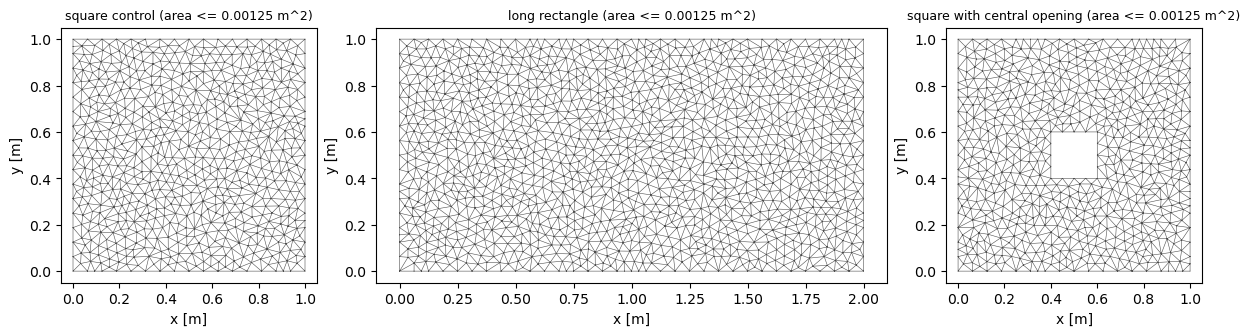

In [23]:
meshes, mesh_rows = {}, []
for oid, obj in OBJECTS.items():
    for a in AREAS:
        meshes[oid, a] = mesh_object(obj, a)
        chk = mesh_checks(obj, *meshes[oid, a])
        mesh_rows.append(dict(object=oid, max_triangle_area_m2=a, **chk))
        print(f"{oid} area<={a:<9g} nodes {chk['nodes']:5d} triangles {chk['triangles']:5d} "
              f"material area {chk['material_area_m2']:.4f} m^2  min angle {chk['min_angle_deg']:.1f} deg  "
              f"centroids in hole {chk['centroids_in_hole']}  edge-connected {chk['edge_connected']}")
        assert chk["min_area_m2"] > 0 and chk["centroids_in_hole"] == 0 and chk["edge_connected"]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), gridspec_kw=dict(width_ratios=[1, 2, 1]), constrained_layout=True)
for ax, oid in zip(axes, OBJECTS):
    nodes, tris = meshes[oid, MID]
    ax.triplot(nodes[:, 0], nodes[:, 1], tris, lw=0.4, color="0.3")
    ax.set_aspect("equal"); ax.set_title(f"{OBJECTS[oid]['name']} (area <= {MID} m^2)", fontsize=9)
    ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
save(fig, "objects_meshes"); plt.show()

### 7.2 Geometry study

Baseline load and clamp, middle mesh. This compares deformation and solver effort across the three shapes.

In [24]:
base = {}
for oid, obj in OBJECTS.items():
    cs = object_case(obj, *meshes[oid, MID])
    d, rec = solve_object(obj, cs, study="geometry", variant="baseline", area=MID, conditioning=True)
    base[oid] = (cs, d, rec)

print(f"{'object':28s} {'unknowns':>8s} {'kappa_2':>9s} {'CG':>5s} {'PCG':>5s} {'mean u_x right [mm]':>20s} {'mid u_x [mm]':>12s} {'mid u_y [mm]':>12s}  checks")
for oid, (cs, d, r) in base.items():
    print(f"{r['object_name']:28s} {r['free_unknowns']:8d} {r['kappa_2']:9.0f} {r['cg_iterations']:5d} {r['pcg_iterations']:5d} "
          f"{mm(r['mean_right_ux_m']):20.5f} {mm(r['mid_ux_m']):12.5f} {mm(r['mid_uy_m']):12.2e}  {ok(r)}")

object                       unknowns   kappa_2    CG   PCG  mean u_x right [mm] mid u_x [mm] mid u_y [mm]  checks
square control                   1282     11240   268   245              0.49363      0.49178    -5.66e-06  pass
long rectangle                   2532    100758   427   395              0.99362      0.99365     2.53e-05  pass
square with central opening      1246     13032   283   256              0.55597      0.58825     4.03e-04  pass


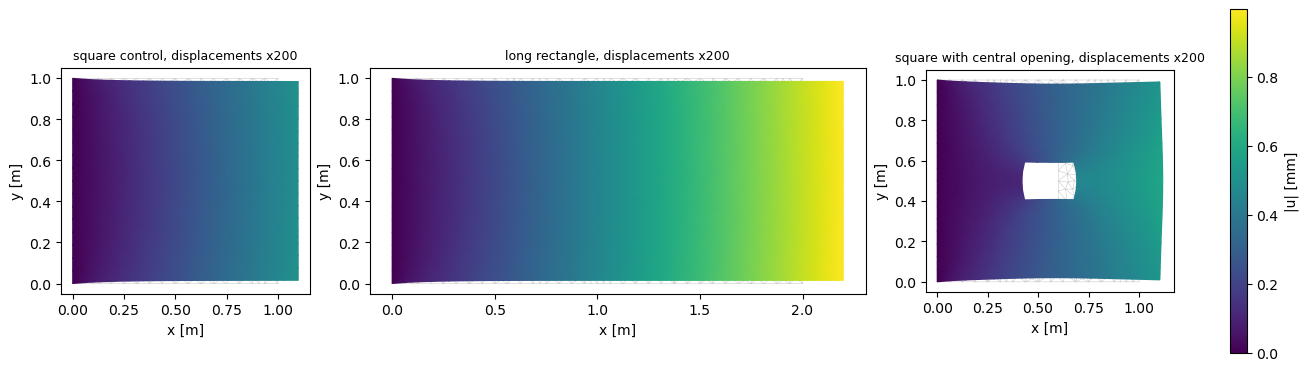

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw=dict(width_ratios=[1, 2, 1]), constrained_layout=True)
vmax = max(np.linalg.norm(d.reshape(-1, 2), axis=1).max() for _, d, _ in base.values()) * 1e3
for ax, (oid, (cs, d, r)) in zip(axes, base.items()):
    tp = plot_deformed(ax, cs["nodes"], cs["triangles"], d, 200, f"{r['object_name']}, displacements x200")
    tp.set_clim(0, vmax)
fig.colorbar(tp, ax=axes, label="|u| [mm]")
save(fig, "objects_deformed"); plt.show()

### 7.3 Mesh study

The same physical case on three meshes per object. Meshes are not nested, so we report the **successive differences** of each observable, signed and absolute, in metres. These measure mesh dependence, not the error against an exact solution, so no convergence rate is inferred.

In [26]:
mesh_study = {}
for oid, obj in OBJECTS.items():
    for a in AREAS:
        cs = object_case(obj, *meshes[oid, a])
        _, mesh_study[oid, a] = solve_object(obj, cs, study="mesh", variant="baseline", area=a, conditioning=True)

OBS = ["mean_right_ux", "mid_ux", "mid_uy"]
diff_rows = []
for oid in OBJECTS:
    for a0, a1 in zip(AREAS[:-1], AREAS[1:]):
        r0, r1 = mesh_study[oid, a0], mesh_study[oid, a1]
        for n in OBS:
            signed = r1[n + "_m"] - r0[n + "_m"]
            est = r0["unc_" + n + "_m"] + r1["unc_" + n + "_m"]
            both_ok = r0["passed_all_checks"] and r1["passed_all_checks"]
            status = ("unverified" if not np.isfinite(est) or not both_ok
                      else "unresolved" if abs(signed) <= est else "resolved")
            diff_rows.append(dict(object=oid, area_from_m2=a0, area_to_m2=a1, observable=n,
                                  value_from_m=r0[n + "_m"], value_to_m=r1[n + "_m"], signed_difference_m=signed,
                                  abs_difference_m=abs(signed), summed_algebraic_estimate_m=est, status=status))

print(f"{'obj':3s} {'area':>9s} {'unknowns':>8s} {'kappa_2':>8s} {'CG':>4s}  " + "  ".join(f"{n + ' [mm]':>18s}" for n in OBS) + "  checks")
for oid in OBJECTS:
    for a in AREAS:
        r = mesh_study[oid, a]
        print(f"{oid:3s} {a:9g} {r['free_unknowns']:8d} {r['kappa_2']:8.0f} {r['cg_iterations']:4d}  "
              + "  ".join(f"{mm(r[n + '_m']):18.6f}" for n in OBS) + f"  {ok(r)}")
print(f"\n{'obj':3s} {'areas':>20s} {'observable':>14s} {'signed diff [m]':>16s} {'summed estimate [m]':>20s}  status")
for row in diff_rows:
    areas = f"{row['area_from_m2']:g} -> {row['area_to_m2']:g}"
    print(f"{row['object']:3s} {areas:>20s} {row['observable']:>14s} "
          f"{row['signed_difference_m']:16.3e} {row['summed_algebraic_estimate_m']:20.1e}  {row['status']}")

obj      area unknowns  kappa_2   CG  mean_right_ux [mm]         mid_ux [mm]         mid_uy [mm]  checks
S       0.005      328     2959  133            0.493196            0.491261           -0.000167  pass
S     0.00125     1282    11240  268            0.493632            0.491779           -0.000006  pass
S   0.0003125     5122    45708  537            0.493799            0.491969           -0.000010  pass
R       0.005      688    27124  222            0.993158            0.993182           -0.000267  pass
R     0.00125     2532   100758  427            0.993623            0.993645            0.000025  pass
R   0.0003125    10166   440830  873            0.993780            0.993801            0.000064  pass
H       0.005      326     3094  139            0.547683            0.574119           -0.000502  pass
H     0.00125     1246    13032  283            0.555967            0.588251            0.000403  pass
H   0.0003125     4866    52727  549            0.559648            0.5

### 7.4 Load magnitude, load location and supports

* **Magnitude:** $0.5F_0$, $F_0$, $1.5F_0$ on the same mesh. In a linear model the displacement must scale exactly with the load. This checks linearity on a fixed matrix, not sensitivity.
* **Location:** the same total force $F_0$ on a lower, middle or upper patch of the right edge, each 0.25 m high (traction 400 MPa).
* **Supports:** the full left clamp vs. a central half-clamp ($y\in[0.25,0.75]$).

In [27]:
F0 = CASES["baseline"]["total_force_N"][0]
print("Magnitude study (mean right-edge u_x [mm]; ratio to the F0 case)")
for oid, obj in OBJECTS.items():
    vals = {}
    for fac in CASES["studies"]["magnitude"]["force_factors"]:
        cs = object_case(obj, *meshes[oid, MID], force=fac * F0)
        _, r = solve_object(obj, cs, study="magnitude", variant=f"{fac:g}F0", area=MID)
        vals[fac] = mm(r["mean_right_ux_m"])
    print(f"  {oid}: " + "  ".join(f"{fac:g}F0 -> {v:.5f} ({v / vals[1]:.6f})" for fac, v in vals.items()))

print("\nLocation study (same total force on a 0.25 m patch)")
print(f"  {'obj':3s} {'patch y [m]':>14s} {'mean u_x right [mm]':>20s} {'mid u_x [mm]':>12s} {'mid u_y [mm]':>12s} {'CG':>5s}  checks")
for oid, obj in OBJECTS.items():
    for y0, y1 in CASES["studies"]["location"]["right_edge_intervals_y_m"]:
        cs = object_case(obj, *meshes[oid, MID], load_y=(y0, y1))
        _, r = solve_object(obj, cs, study="location", variant=f"y=[{y0:g},{y1:g}]", area=MID)
        print(f"  {oid:3s} {f'[{y0:g}, {y1:g}]':>14s} {mm(r['mean_right_ux_m']):20.5f} {mm(r['mid_ux_m']):12.5f} "
              f"{mm(r['mid_uy_m']):12.5f} {r['cg_iterations']:5d}  {ok(r)}")

print("\nSupport study (full-edge load)")
print(f"  {'obj':3s} {'clamp y [m]':>12s} {'unknowns':>8s} {'mean u_x right [mm]':>20s} {'mid u_y [mm]':>12s} {'kappa_2':>9s} {'CG':>5s}  checks")
for oid, obj in OBJECTS.items():
    for y0, y1 in CASES["studies"]["supports"]["left_clamp_intervals_y_m"]:
        cs = object_case(obj, *meshes[oid, MID], clamp_y=(y0, y1))
        _, r = solve_object(obj, cs, study="supports", variant=f"clamp y=[{y0:g},{y1:g}]", area=MID, conditioning=True)
        print(f"  {oid:3s} {f'[{y0:g}, {y1:g}]':>12s} {r['free_unknowns']:8d} {mm(r['mean_right_ux_m']):20.5f} "
              f"{mm(r['mid_uy_m']):12.5f} {r['kappa_2']:9.0f} {r['cg_iterations']:5d}  {ok(r)}")

Magnitude study (mean right-edge u_x [mm]; ratio to the F0 case)


  S: 0.5F0 -> 0.24682 (0.500000)  1F0 -> 0.49363 (1.000000)  1.5F0 -> 0.74045 (1.500000)


  R: 0.5F0 -> 0.49681 (0.500000)  1F0 -> 0.99362 (1.000000)  1.5F0 -> 1.49044 (1.500000)
  H: 0.5F0 -> 0.27798 (0.500000)  1F0 -> 0.55597 (1.000000)  1.5F0 -> 0.83395 (1.500000)

Location study (same total force on a 0.25 m patch)
  obj    patch y [m]  mean u_x right [mm] mid u_x [mm] mid u_y [mm]    CG  checks


  S        [0, 0.25]              0.49487      0.28732      1.07210   273  pass
  S   [0.375, 0.625]              0.49196      0.90866     -0.00059   272  pass
  S        [0.75, 1]              0.49488      0.28786     -1.07204   273  pass


  R        [0, 0.25]              0.99361      0.78786      4.42238   431  pass
  R   [0.375, 0.625]              0.99364      1.41233      0.00035   424  pass


  R        [0.75, 1]              0.99360      0.78764     -4.42231   431  pass
  H        [0, 0.25]              0.53578      0.34514      1.08415   277  pass
  H   [0.375, 0.625]              0.58443      1.05886      0.00348   276  pass


  H        [0.75, 1]              0.53584      0.34549     -1.08414   276  pass

Support study (full-edge load)
  obj  clamp y [m] unknowns  mean u_x right [mm] mid u_y [mm]   kappa_2    CG  checks
  S         [0, 1]     1282              0.49363     -0.00001     11240   268  pass
  S   [0.25, 0.75]     1300              0.60403      0.00496     33227   307  pass


  R         [0, 1]     2532              0.99362      0.00003    100758   427  pass


  R   [0.25, 0.75]     2550              1.10465     -0.00378    242073   456  pass
  H         [0, 1]     1246              0.55597      0.00040     13032   283  pass
  H   [0.25, 0.75]     1266              0.69620     -0.00791     36291   325  pass


### 7.5 Acceptance summary

Every case solved in Part 7, with each check recorded separately.

In [28]:
CHECKS = ["structure", "symmetry", "spd", "residual", "supports", "force_balance", "moment_balance"]
print(f"{'case':42s} " + " ".join(f"{c[:9]:>9s}" for c in CHECKS) + f" {'residual':>9s} {'force':>8s} {'moment':>8s}")
for r in RESULTS:
    print(f"{r['case_id']:42s} " + " ".join(f"{r['check_' + c]:>9s}" for c in CHECKS)
          + f" {r['value_residual']:9.1e} {r['value_force_balance']:8.1e} {r['value_moment_balance']:8.1e}")
n_pass = sum(r["passed_all_checks"] for r in RESULTS)
print(f"\n{n_pass} of {len(RESULTS)} cases pass every check")

case                                       structure  symmetry       spd  residual  supports force_bal moment_ba  residual    force   moment
S|geometry|baseline|a=0.00125                   pass      pass      pass      pass      pass      pass      pass   4.1e-14  1.5e-14  5.7e-15
R|geometry|baseline|a=0.00125                   pass      pass      pass      pass      pass      pass      pass   1.2e-13  3.9e-14  4.8e-15
H|geometry|baseline|a=0.00125                   pass      pass      pass      pass      pass      pass      pass   4.4e-14  4.9e-15  9.0e-16
S|mesh|baseline|a=0.005                         pass      pass      pass      pass      pass      pass      pass   1.1e-14  2.8e-15  2.5e-16
S|mesh|baseline|a=0.00125                       pass      pass      pass      pass      pass      pass      pass   4.1e-14  1.5e-14  5.7e-15
S|mesh|baseline|a=0.0003125                     pass      pass      pass      pass      pass      pass      pass   1.4e-13  5.6e-15  2.0e-15
R|mesh|baseli

## 8. Exported results

Every table and figure above is written to `outputs/` next to this notebook, so the report can cite a traceable source:

* `outputs/results/objects_cases.csv`: one row per Part 7 case (case ID, mesh size, observables in metres, algebraic estimates, κ, iterations, every acceptance check and value);
* `outputs/results/objects_mesh_differences.csv`: successive-mesh differences (signed and absolute) with the resolution status;
* `outputs/results/objects_meshes.csv`: mesh sizes and quality;
* `outputs/results/structured_solvers.csv`, `structured_refinement.csv`, `structured_validation.json`: Parts 3–6 (structured meshes);
* `outputs/results/manifest.json`: environment, the source of the specification, observable and κ definitions, thresholds;
* `outputs/figures/*.png`.

In [29]:
import csv
def write_csv(path, rows):
    with open(path, "w", newline="") as fh:
        keys = list(dict.fromkeys(k for r in rows for k in r))
        w = csv.DictWriter(fh, fieldnames=keys); w.writeheader(); w.writerows(rows)

RES = OUT / "results"
write_csv(RES / "objects_cases.csv", RESULTS)
write_csv(RES / "objects_mesh_differences.csv", diff_rows)
write_csv(RES / "objects_meshes.csv", mesh_rows)
write_csv(RES / "structured_solvers.csv",
          [dict(method=m, iterations=k, status=s, relative_residual=rr, relative_error_vs_lu=err, best_seconds=tm,
                mesh="20x20 structured", free_unknowns=len(b)) for m, k, s, rr, err, tm in rows])
write_csv(RES / "structured_refinement.csv",
          [dict(cells=f"{r[0]}x{r[0]}", free_unknowns=r[1], stored_nnz=r[2], kappa_2=r[3], cg_iterations=r[4],
                top_right_ux_mm=r[5]) for r in refine])
(RES / "structured_validation.json").write_text(json.dumps(dict(
    small_2x2=dict(unknowns=len(b_s), kappa_2=float(ev[-1] / ev[0])),
    net_force_N=F_net.tolist(), net_moment_Nm=M_net,
    roller_relative_error=float(np.linalg.norm(d_r - exact) / np.linalg.norm(exact)),
    perturbation=dict(relative_load=1e-6, relative_displacement=float(np.linalg.norm(dx) / np.linalg.norm(x_ref)), seed=2026),
    jacobi_spectral_radius=float(max(abs(1 - s_lo), abs(1 - s_hi)))), indent=2))
manifest = dict(
    specification_source=CASES_SOURCE, specification_status_field=CASES["status"],
    environment=dict(python=platform.python_version(), numpy=np.__version__, scipy=scipy.__version__,
                     matplotlib=matplotlib.__version__, triangle=str(getattr(tr, "__version__", "")), platform=platform.platform()),
    material=dict(E_Pa=E, nu=NU, thickness_m=T, model="plane stress"),
    observables=dict(mean_right_ux="integral of u_x over the whole right edge / its length (exact for the piecewise-linear trace), metres",
                     mid_ux="u_x at the right-edge midpoint (x_r, 0.5), metres",
                     mid_uy="u_y at the right-edge midpoint (x_r, 0.5), metres"),
    condition_number="kappa_2 = lambda_max / lambda_min of the supported (free-free), unscaled stiffness matrix A; "
                     "lambda_max by ARPACK (largest algebraic), lambda_min by ARPACK shift-invert at 0",
    algebraic_estimate="||w_free||_2 ||b - A x_ref||_2 / lambda_min_est; an estimate, not a certified bound; a successive difference "
                       "<= the sum of both meshes' estimates is 'unresolved'",
    solver_protocol=dict(tolerance=TOL, iteration_cap=CAP, x0="zero", timing="best of 3 runs; machine dependent"),
    acceptance_thresholds=CASES["proposed_acceptance"],
    cases_total=len(RESULTS), cases_passing_all_checks=int(n_pass))
(RES / "manifest.json").write_text(json.dumps(manifest, indent=2, default=str))
for p in sorted(OUT.rglob("*.*")):
    print(p, p.stat().st_size, "bytes")

outputs/figures/objects_deformed.png 385864 bytes
outputs/figures/objects_meshes.png 1063244 bytes
outputs/figures/structured_deformed_20x20.png 166003 bytes
outputs/figures/structured_refinement.png 56878 bytes
outputs/figures/structured_residual_histories.png 148252 bytes
outputs/figures/structured_small_sparsity.png 20071 bytes
outputs/results/manifest.json 3880 bytes
outputs/results/objects_cases.csv 17898 bytes
outputs/results/objects_mesh_differences.csv 2820 bytes
outputs/results/objects_meshes.csv 799 bytes
outputs/results/structured_refinement.csv 244 bytes
outputs/results/structured_solvers.csv 961 bytes
outputs/results/structured_validation.json 414 bytes


## 9. Summary

The cell below recomputes the headline comparisons from the exported results, so the text and the numbers cannot drift apart.

**What the structured-square study (Parts 3–6) shows**
* The supported stiffness matrix $A$ is sparse, symmetric and positive definite, as the energy argument predicts. Its condition number grows like $h^{-2}$.
* All direct methods solve the small system to rounding accuracy. On the larger system, Krylov methods (CG, PCG, MINRES, GMRES) need a few hundred iterations, while Gauss–Seidel needs tens of thousands. CG is the natural choice for an SPD matrix: it is fastest and needs the least memory.
* Positive definiteness does **not** guarantee that Jacobi converges. Here $\rho(I-D_A^{-1}A)\approx1.96>1$.
* Equilibrium and an exact linear solution confirm that the assembled model is correct, not just that the linear system was solved.

**What the other objects (Part 7) show**, for the specification of report §5
* All cases pass every acceptance check.
* The mesh-to-mesh differences are far above the algebraic uncertainty estimates, so they reflect discretization, not solver error.
* The square with an opening changes much more between meshes than the plain square or the rectangle. This is consistent with stress concentrating at its re-entrant corners, but the measurements alone do not prove the cause or give a convergence rate.
* At the right-edge midpoint, $u_y$ is close to zero by symmetry (for S and H), and its successive differences are of the same order as its value. It should not be interpreted as a physical result.

In [30]:
g = {r["object"]: r for r in RESULTS if r["study"] == "geometry"}
print(f"mean right-edge u_x:  R / S = {g['R']['mean_right_ux_m'] / g['S']['mean_right_ux_m']:.3f},  "
      f"H / S = {g['H']['mean_right_ux_m'] / g['S']['mean_right_ux_m']:.3f}")
print(f"kappa_2 (same mesh-area limit {MID}):  R / S = {g['R']['kappa_2'] / g['S']['kappa_2']:.2f},  "
      f"H / S = {g['H']['kappa_2'] / g['S']['kappa_2']:.2f}")
for oid in OBJECTS:
    d_last = [r for r in diff_rows if r["object"] == oid and r["observable"] == "mean_right_ux"][-1]
    print(f"{oid}: last successive change in mean right-edge u_x = {d_last['abs_difference_m']:.2e} m "
          f"({100 * d_last['abs_difference_m'] / abs(d_last['value_to_m']):.3f}% of its value), {d_last['status']}")
sup = {(r["object"], r["variant"]): r for r in RESULTS if r["study"] == "supports"}
for oid in OBJECTS:
    full, half = sup[oid, "clamp y=[0,1]"], sup[oid, "clamp y=[0.25,0.75]"]
    print(f"{oid}: half clamp vs full clamp: mean u_x x{half['mean_right_ux_m'] / full['mean_right_ux_m']:.3f}, "
          f"kappa_2 x{half['kappa_2'] / full['kappa_2']:.2f}")

mean right-edge u_x:  R / S = 2.013,  H / S = 1.126
kappa_2 (same mesh-area limit 0.00125):  R / S = 8.96,  H / S = 1.16
S: last successive change in mean right-edge u_x = 1.67e-07 m (0.034% of its value), resolved
R: last successive change in mean right-edge u_x = 1.56e-07 m (0.016% of its value), resolved
H: last successive change in mean right-edge u_x = 3.68e-06 m (0.658% of its value), resolved
S: half clamp vs full clamp: mean u_x x1.224, kappa_2 x2.96
R: half clamp vs full clamp: mean u_x x1.112, kappa_2 x2.40
H: half clamp vs full clamp: mean u_x x1.252, kappa_2 x2.78


## Code provenance and AI use

The finite-element assembly, load/support handling and solver protocol in this notebook are self-contained copies of the group repository's `fem/elasticity.py`, `fem/plate.py`, `solvers/system_tools.py` and `solvers/progress_benchmark.py`. The Part 7 case specification and acceptance criteria come from report §5 (`cases.json` @ `2b23fd5`). Library routines: SciPy (sparse LU, CG, GMRES, MINRES, ARPACK eigenvalues) and Triangle by J. R. Shewchuk, via the `triangle` Python package (meshing). AI assistance was used in writing this code. See the AI-use statement in the report.